In [5]:
from langchain_ollama import ChatOllama
model = ChatOllama(model="llama3.2:latest")
print('Model is ready')

Model is ready


In [6]:
#tools definition
from langchain_core.tools import tool

@tool
def billing_tool(query: str) -> str:
    """Handle payment and billing related issues"""
    return f"Billing Team: Processing -> {query}"


@tool
def technical_tool(query: str) -> str:
    """Handle technical issues"""
    return f"Technical Support Team: Processing -> {query}"


@tool
def refund_tool(query: str) -> str:
    """Handle refund requests"""
    return f"Refund Team: Processing -> {query}"


@tool
def general_tool(query: str) -> str:
    """Handle general employee queries"""
    return f"General Support Team: Processing -> {query}"

ALL_TOOLS = [billing_tool, technical_tool, refund_tool, general_tool]
print('Tools are ready')

Tools are ready


In [7]:
# STEP 1: Define your state
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import AnyMessage

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [8]:
# STEP 2: Define your nodes
model_with_tools = model.bind_tools(ALL_TOOLS)

def assistant_node(state: AgentState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model_with_tools.invoke(state['messages'])
    return {"messages": [response]}

def route_after_assistant_node(state: AgentState) -> str:
    """Route to tools only when model produces tool calls"""
    last_message = state['messages'][-1]
    if last_message.tool_calls:
        return "tools_key"
    return "end_key"
print('Nodes are defined')

Nodes are defined


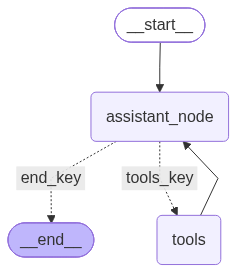

In [14]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)
graph_builder.add_node("tools", ToolNode(ALL_TOOLS))

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_conditional_edges(
    "assistant_node",
    route_after_assistant_node,
    {
        "tools_key": "tools",
        "end_key": END
    }
)
graph_builder.add_edge("tools", "assistant_node")
graph = graph_builder.compile()
graph


In [10]:
response = graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "My salary has not been credited."
            }
        ]
    }
)

print(response)

{'messages': [HumanMessage(content='My salary has not been credited.', additional_kwargs={}, response_metadata={}, id='94d0a227-14fa-4858-a204-e0718b05143c'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-25T10:15:19.1244187Z', 'done': True, 'done_reason': 'stop', 'total_duration': 18146035300, 'load_duration': 6773017400, 'prompt_eval_count': 271, 'prompt_eval_duration': 8106341000, 'eval_count': 22, 'eval_duration': 3223463000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a1728e-7467-740e-94ac-75514e3ed008-0', tool_calls=[{'name': 'general_tool', 'args': {'query': 'My salary has not been credited'}, 'id': 'f219cc9b-ed39-4d42-ad47-572485d4ca13', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 271, 'output_tokens': 22, 'total_tokens': 293}), ToolMessage(content='General Support Team: Processing -> My salary has not been credited', name='gene

In [11]:
response = graph.invoke({"messages": [{
                "role": "user",
                "content": "I am unable to login to VPN."
            }]}
)

print(response)

{'messages': [HumanMessage(content='I am unable to login to VPN.', additional_kwargs={}, response_metadata={}, id='a5705ea3-c08f-492f-bdfe-34bcb0eeecf1'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-25T10:15:48.3561264Z', 'done': True, 'done_reason': 'stop', 'total_duration': 2725924500, 'load_duration': 12239900, 'prompt_eval_count': 272, 'prompt_eval_duration': 627932000, 'eval_count': 17, 'eval_duration': 2058266000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a1728f-22db-7334-bb98-83c8bb1517fb-0', tool_calls=[{'name': 'technical_tool', 'args': {'query': 'Unable to login to VPN'}, 'id': '62558258-5396-4839-b9bd-b690e1f36183', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 272, 'output_tokens': 17, 'total_tokens': 289}), ToolMessage(content='Technical Support Team: Processing -> Unable to login to VPN', name='technical_tool', id='4a0c5

In [15]:
response = graph.invoke({"messages": [{
                "role": "user",
                "content": "I need refund or reimbursement for travel expenses."
            }]}
)

print(response)

{'messages': [HumanMessage(content='I need refund or reimbursement for travel expenses.', additional_kwargs={}, response_metadata={}, id='1e6e0c9c-a745-4f0a-beb9-a19c4a3792a8'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-25T10:23:46.0314837Z', 'done': True, 'done_reason': 'stop', 'total_duration': 3218020600, 'load_duration': 14638500, 'prompt_eval_count': 273, 'prompt_eval_duration': 177294000, 'eval_count': 22, 'eval_duration': 2991272000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17296-6adb-74f3-b5c9-4d3c9543611e-0', tool_calls=[{'name': 'refund_tool', 'args': {'query': 'refund or reimbursement for travel expenses'}, 'id': '576f2bb1-2c21-42f6-a07c-705d6580ec00', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 273, 'output_tokens': 22, 'total_tokens': 295}), ToolMessage(content='Refund Team: Processing -> refund or reimbursement for

In [16]:
response = graph.invoke({"messages": [{
                "role": "user",
                "content": "I have a suggestion for improving cafeteria services."
            }]}
)

print(response)

{'messages': [HumanMessage(content='I have a suggestion for improving cafeteria services.', additional_kwargs={}, response_metadata={}, id='f618ab9e-5d00-4745-a161-852ae2cdb121'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'llama3.2:latest', 'created_at': '2026-10-25T10:25:52.4148912Z', 'done': True, 'done_reason': 'stop', 'total_duration': 2963726700, 'load_duration': 12947900, 'prompt_eval_count': 273, 'prompt_eval_duration': 443850000, 'eval_count': 20, 'eval_duration': 2480360000, 'logprobs': None, 'model_name': 'llama3.2:latest', 'model_provider': 'ollama'}, id='lc_run--01a17298-5988-73b4-9d7e-29d147c07f64-0', tool_calls=[{'name': 'general_tool', 'args': {'query': 'Improve cafeteria services'}, 'id': 'f902095d-fcb8-4a6a-850d-272d300789ad', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 273, 'output_tokens': 20, 'total_tokens': 293}), ToolMessage(content='General Support Team: Processing -> Improve cafeteria services', nam